# Naive Altitude and Vertical Velocity Estimation

See how well the accelerometer and barometer can each estimate altitude (h) and vertical velocity (v) on their own. A static recording shows each sensor's noise and drift. A stair-climbing recording shows where each one fails. Press `shift + enter` to run each cell.

In [1]:
import numpy as np

import utils

## Settings

In [2]:
# Recordings (folders containing acc_baro.csv and meta.json)
REST_PATH = "recordings/static"
STAIRS_PATH = "recordings/stairs_up"

# Every recording starts with the board held still for at least this long
# (seconds). We use this window to remove gravity and accelerometer bias.
STILL_S = 4.0
STILL_THRESH = 0.4

# Ground truth for the stairs recording (count the steps, measure one riser)
NUM_STEPS = 16
RISER_M = 0.193

## Helper Functions

As in the pitch notebooks, we use *for loops* rather than NumPy array math, since they are closer to what we would run on a microcontroller.

In [3]:
def accel_to_vertical(t, az, window):
    """
    Remove gravity and accelerometer bias by subtracting the mean z-axis
    reading over a still window (t_start, t_end). Returns (a, g_est).
    """
    t0, t1 = window
    still = (t >= t0) & (t <= t1)
    g_est = np.mean(az[still])

    return az - g_est, g_est

In [4]:
def integrate_accel(t, a):
    """
    Double-integrate vertical acceleration to get velocity and altitude,
    assuming the board starts at rest at h = 0. Uses constant-acceleration
    kinematics between samples (the same model the Kalman filter will use).
    """
    v = np.zeros(len(a))
    h = np.zeros(len(a))
    for i in range(1, len(a)):
        dt = t[i] - t[i - 1]
        v[i] = v[i - 1] + a[i - 1] * dt
        h[i] = h[i - 1] + v[i - 1] * dt + 0.5 * a[i - 1] * dt**2

    return v, h

In [5]:
def velocity_from_baro(t, alt):
    """Differentiate barometer altitude (finite difference) to get velocity."""
    v = np.zeros(len(alt))
    for i in range(1, len(alt)):
        v[i] = (alt[i] - alt[i - 1]) / (t[i] - t[i - 1])

    return v

In [6]:
def moving_average(x, n):
    """
    Trailing moving average over the last n samples. It only uses past data,
    just like a filter running in real time on a microcontroller.
    """
    out = np.zeros(len(x))
    for i in range(len(x)):
        start = max(0, i - n + 1)
        out[i] = np.mean(x[start:i + 1])

    return out

## Static Recording: Raw Data

The board sits flat and still for 5 minutes, so the true altitude and velocity are both zero the whole time. Anything we see is noise or drift.

In [7]:
# Load the static recording
rest, rest_meta = utils.load_recording(REST_PATH)
t_acc = rest["t"]
az = rest["az"]

# Pull out the barometer samples (each one appears once)
t_baro, alt = utils.baro_samples(rest)

# Print a summary
print(f"Notes: {rest_meta['notes']}")
print(f"Duration: {t_acc[-1]:.1f} s")
print(f"Accel samples: {len(t_acc)}  ({1 / np.median(np.diff(t_acc)):.1f} Hz)")
print(f"Baro samples:  {len(t_baro)}  ({1 / np.median(np.diff(t_baro)):.1f} Hz)")

Notes: 
Duration: 300.0 s
Accel samples: 37371  (123.1 Hz)
Baro samples:  14986  (60.3 Hz)


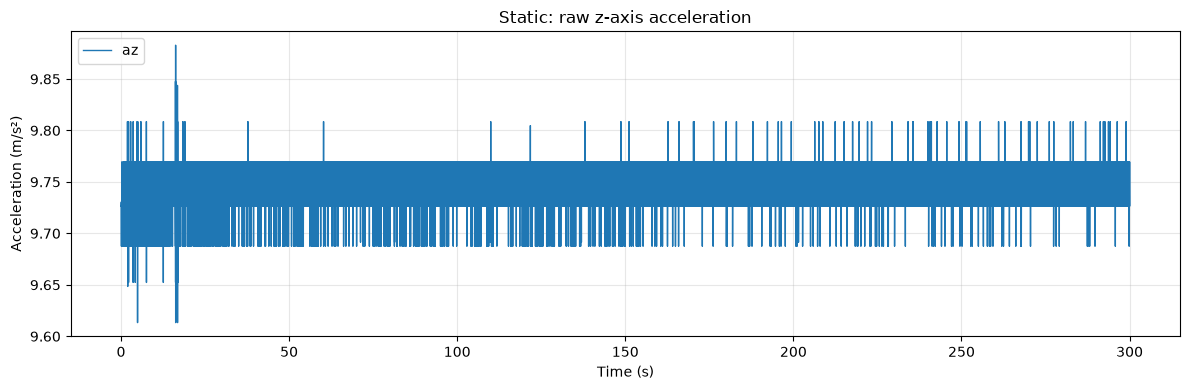

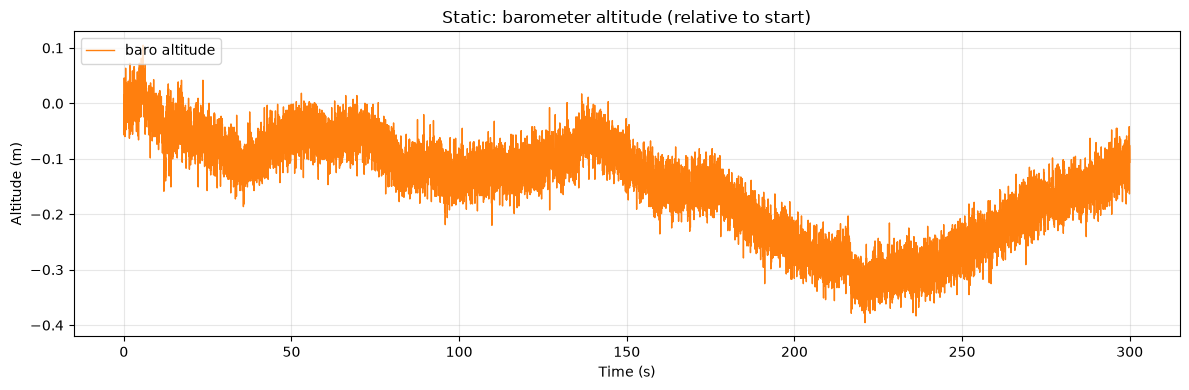

In [8]:
# Barometric altitude is offset by the weather, so make it relative to the
# start of the recording
alt_rel = alt - np.mean(alt[t_baro < t_baro[0] + STILL_S])

# Plot raw acceleration and relative altitude
utils.plot_traces(
    [(t_acc, az, "az", {"color": "tab:blue"})],
    "Acceleration (m/s²)",
    title="Static: raw z-axis acceleration",
)
utils.plot_traces(
    [(t_baro, alt_rel, "baro altitude", {"color": "tab:orange"})],
    "Altitude (m)",
    title="Static: barometer altitude (relative to start)",
)

## Static Recording: Noise

Over a short window, the readings scatter randomly around a constant value. The standard deviations here are the noise levels we will use to tune the Kalman filter: σₐ for the accelerometer and σ_b for the barometer.

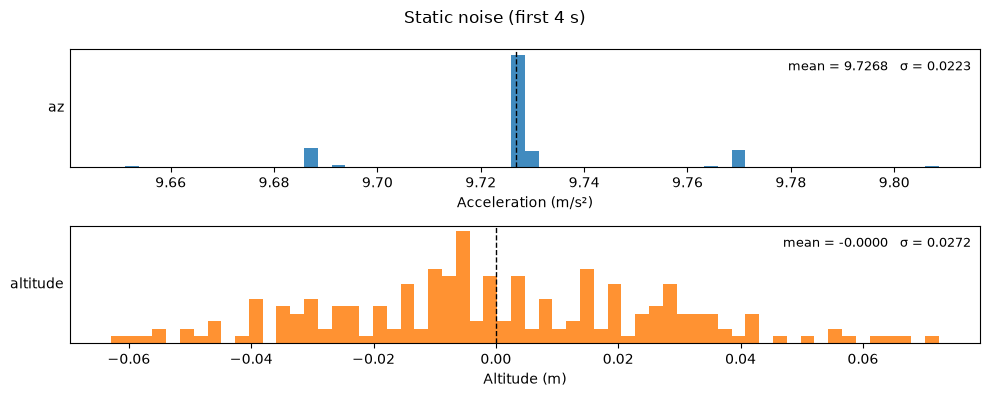

Accelerometer noise (sigma_a): 0.0223 m/s²
Barometer noise (sigma_b):     0.0272 m


In [9]:
# Use only the first few seconds, where noise dominates over drift
short_acc = t_acc < t_acc[0] + STILL_S
short_baro = t_baro < t_baro[0] + STILL_S

# Plot histograms
utils.plot_histograms(
    [
        ("az", az[short_acc], "tab:blue"),
        ("altitude", alt_rel[short_baro], "tab:orange"),
    ],
    title=f"Static noise (first {STILL_S:.0f} s)",
    xlabel=["Acceleration (m/s²)", "Altitude (m)"],
)

# Noise levels (standard deviations)
sigma_a = np.std(az[short_acc], ddof=1)
sigma_b = np.std(alt_rel[short_baro], ddof=1)
print(f"Accelerometer noise (sigma_a): {sigma_a:.4f} m/s²")
print(f"Barometer noise (sigma_b):     {sigma_b:.4f} m")

In [10]:
# Compare with the standard deviation over the full recording
print(f"az std:       first {STILL_S:.0f} s = {sigma_a:.4f} m/s²   "
      f"full = {np.std(az, ddof=1):.4f} m/s²")
print(f"altitude std: first {STILL_S:.0f} s = {sigma_b:.4f} m      "
      f"full = {np.std(alt_rel, ddof=1):.4f} m")

az std:       first 4 s = 0.0223 m/s²   full = 0.0221 m/s²
altitude std: first 4 s = 0.0272 m      full = 0.0897 m



The accelerometer's standard deviation barely changes with a longer window: its noise is random from sample to sample. The barometer's grows, because the air pressure in the room slowly wanders (HVAC, doors, weather). That slow wander is drift, not noise, and it shows up on longer timescales.

## Static Recording: Barometer Drift

Averaging over a few seconds hides the sample-to-sample noise and reveals the slow wander underneath.

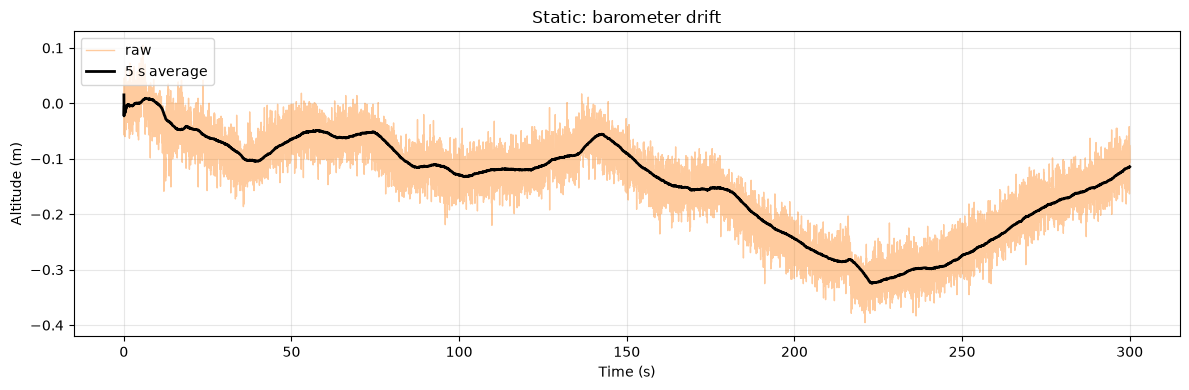

Drift range (5 s average): 0.333 m


In [11]:
# Average over 5 seconds of barometer samples
baro_rate = 1 / np.median(np.diff(t_baro))
n_avg = int(5.0 * baro_rate)
alt_avg = moving_average(alt_rel, n_avg)

# Plot raw vs. averaged altitude
utils.plot_traces(
    [
        (t_baro, alt_rel, "raw", {"color": "tab:orange", "alpha": 0.4}),
        (t_baro, alt_avg, "5 s average", {"color": "k", "lw": 2}),
    ],
    "Altitude (m)",
    title="Static: barometer drift",
)

# How far did the averaged altitude wander?
settled = alt_avg[n_avg:]
print(f"Drift range (5 s average): {settled.max() - settled.min():.3f} m")

The barometer wanders, but it never runs away: the error stays bounded no matter how long we wait. That makes it good for long-term altitude, but it can't reliably detect small, slow changes in height.

## Static Recording: Accelerometer Drift

To get altitude from the accelerometer, we first remove gravity (and the sensor's bias) by subtracting the average reading from the first still window. Then we integrate once to get velocity, and again to get altitude. The board never moves, so both should stay at zero.

In [14]:
# Remove gravity and bias using only the first still window
a_rest, g_est = accel_to_vertical(t_acc, az, (t_acc[0], t_acc[0] + STILL_S))
print(f"Gravity + bias estimate: {g_est:.4f} m/s²")
print(f"Leftover bias over the full recording: {np.mean(a_rest):+.5f} m/s²")

# Double-integrate
v_acc, h_acc = integrate_accel(t_acc, a_rest)

Gravity + bias estimate: 9.7268 m/s²
Leftover bias over the full recording: +0.01526 m/s²


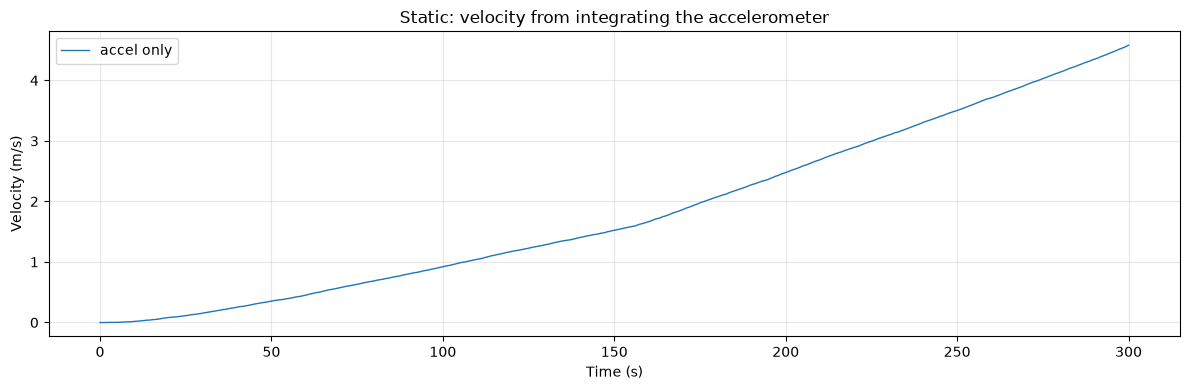

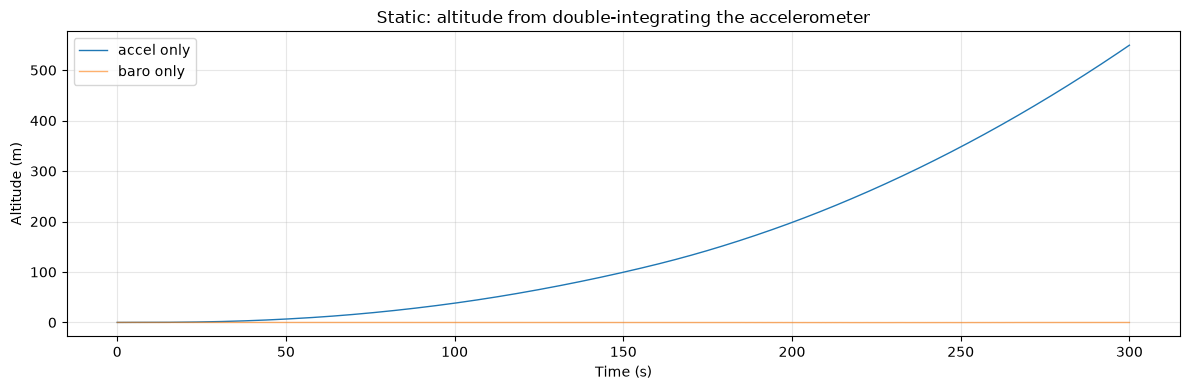

After 300 s: v = +4.581 m/s, h = +549.42 m


In [15]:
# Plot velocity from the accelerometer
utils.plot_traces(
    [(t_acc, v_acc, "accel only", {"color": "tab:blue"})],
    "Velocity (m/s)",
    title="Static: velocity from integrating the accelerometer",
)

# Plot altitude from the accelerometer vs. the barometer
utils.plot_traces(
    [
        (t_acc, h_acc, "accel only", {"color": "tab:blue"}),
        (t_baro, alt_rel, "baro only", {"color": "tab:orange", "alpha": 0.6}),
    ],
    "Altitude (m)",
    title="Static: altitude from double-integrating the accelerometer",
)

print(f"After {t_acc[-1]:.0f} s: v = {v_acc[-1]:+.3f} m/s, h = {h_acc[-1]:+.2f} m")

In [16]:
# A constant leftover bias b grows as 1/2 * b * t^2 when double-integrated
b = np.mean(a_rest)
T = t_acc[-1] - t_acc[0]
print(f"Predicted from the leftover bias alone: h = 1/2 * b * t^2 = {0.5 * b * T**2:+.2f} m")

Predicted from the leftover bias alone: h = 1/2 * b * t^2 = +686.86 m


Even a tiny leftover bias, a few thousandths of a m/s² or less, turns into meters of altitude error within minutes. The rest of the error comes from integrating the random noise, which turns into a random walk. The accelerometer is great for short-term motion but useless on its own for long-term altitude.

## Stairs Recording: Raw Data

Now we climb stairs. The board starts and ends at rest, so we'll mark where the motion happens and treat everything else as still.

In [18]:
# Load the stairs recording
stairs, stairs_meta = utils.load_recording(STAIRS_PATH)
t_acc_s = stairs["t"]
az_s = stairs["az"]
t_baro_s, alt_s = utils.baro_samples(stairs)
print(f"Notes: {stairs_meta['notes']}")
print(f"Duration: {t_acc_s[-1]:.1f} s")

Notes: smooth up stairs, 16 stairs (~309 cm)
Duration: 20.0 s


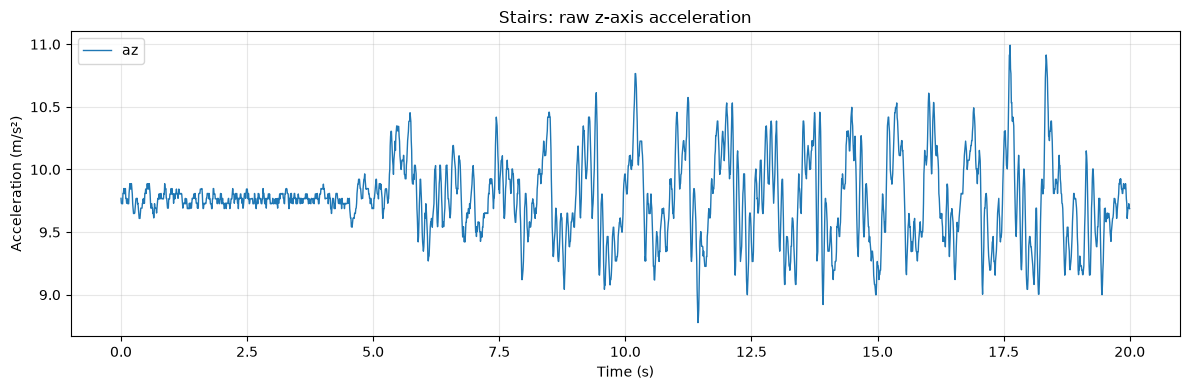

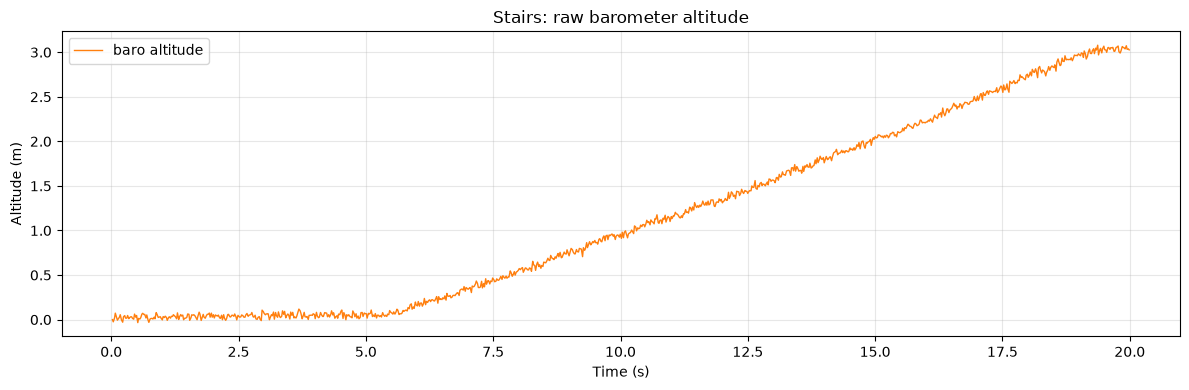

In [19]:
# Plot raw data (altitude relative to the first sample, for readability)
utils.plot_traces(
    [(t_acc_s, az_s, "az", {"color": "tab:blue"})],
    "Acceleration (m/s²)",
    title="Stairs: raw z-axis acceleration",
)
utils.plot_traces(
    [(t_baro_s, alt_s - alt_s[0], "baro altitude", {"color": "tab:orange"})],
    "Altitude (m)",
    title="Stairs: raw barometer altitude",
)

### Mark the Motion

Look at the plots above and find where the motion starts and stops. The footstep spikes in the acceleration and the ramp in the altitude make it easy to see. Enter each motion segment as (start, end) in seconds, then run the cell. The green shading should cover only the flat, still parts. Adjust and re-run until it does.

Still window 0:    0.0 s to    5.0 s
Still window 1:   19.5 s to   20.0 s


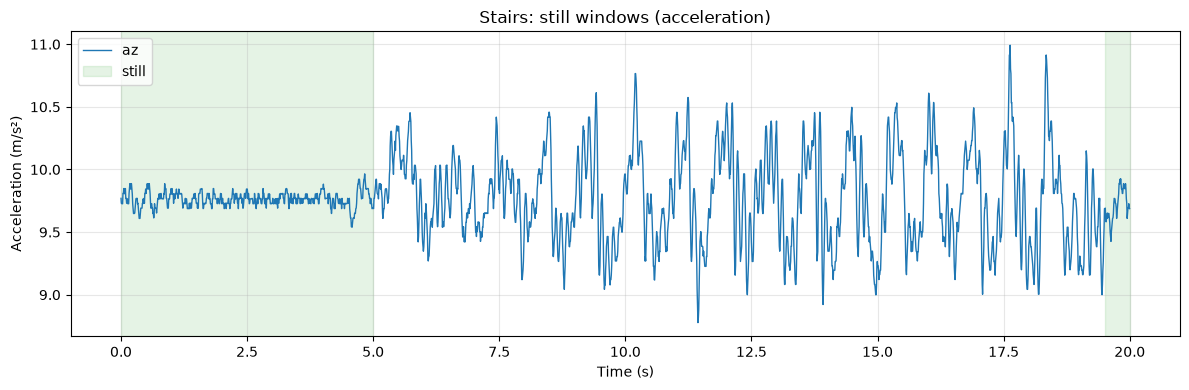

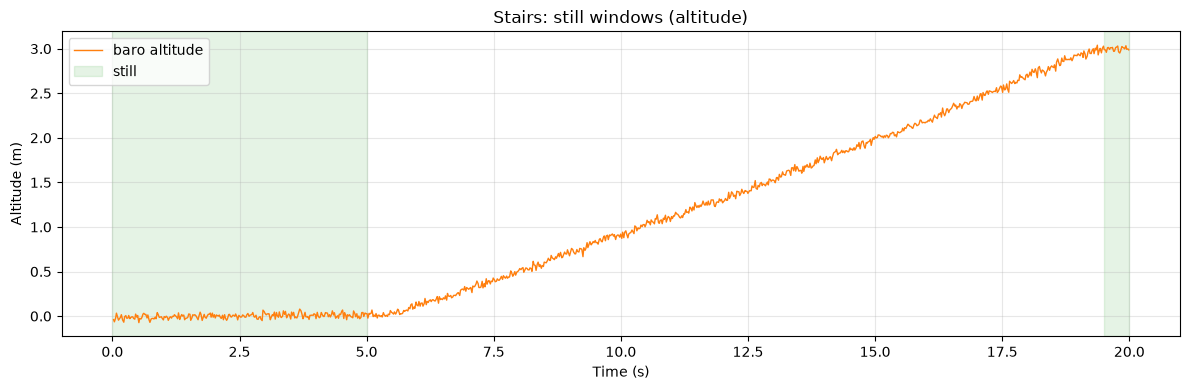

In [23]:
# Motion segments (start, end) in seconds. Add one per climb, e.g.
# [(5.0, 14.1), (22.3, 31.0)] for two flights with a landing pause.
MOTION = [(5.5, 19.0)]

# Everything between the motion segments is still
windows = utils.still_windows(MOTION, t_acc_s[0], t_acc_s[-1])
for i, (t0, t1) in enumerate(windows):
    print(f"Still window {i}: {t0:6.1f} s to {t1:6.1f} s")

# Make altitude relative to the first still window
alt_s_rel = alt_s - utils.window_mean(t_baro_s, alt_s, windows[0])

# Check the still windows against the data
utils.plot_traces(
    [(t_acc_s, az_s, "az", {"color": "tab:blue"})],
    "Acceleration (m/s²)",
    title="Stairs: still windows (acceleration)",
    windows=windows,
)
utils.plot_traces(
    [(t_baro_s, alt_s_rel, "baro altitude", {"color": "tab:orange"})],
    "Altitude (m)",
    title="Stairs: still windows (altitude)",
    windows=windows,
)

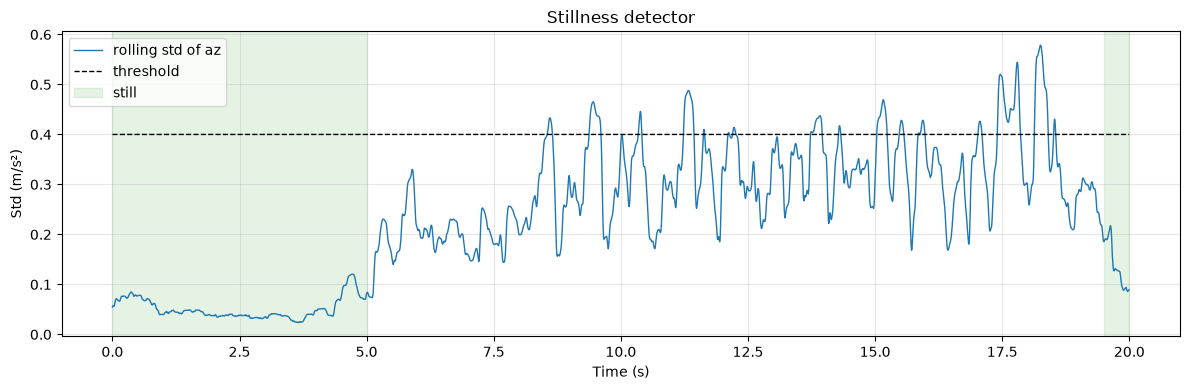

In [24]:
# Diagnostic: rolling std of az vs. the threshold
THRESH = 0.4
n = 50  # 0.5 s at 100 Hz
az_std = np.array([np.std(az_s[max(0, i - n // 2):i + n // 2 + 1])
                   for i in range(len(az_s))])
utils.plot_traces(
    [
        (t_acc_s, az_std, "rolling std of az", {"color": "tab:blue"}),
        (t_acc_s, np.full(len(t_acc_s), THRESH), "threshold",
         {"color": "k", "ls": "--"}),
    ],
    "Std (m/s²)",
    title="Stillness detector",
    windows=windows,
)

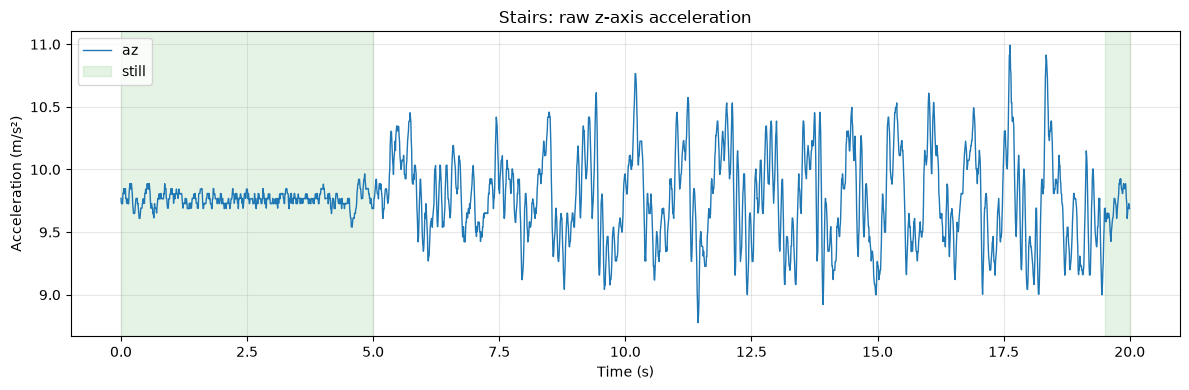

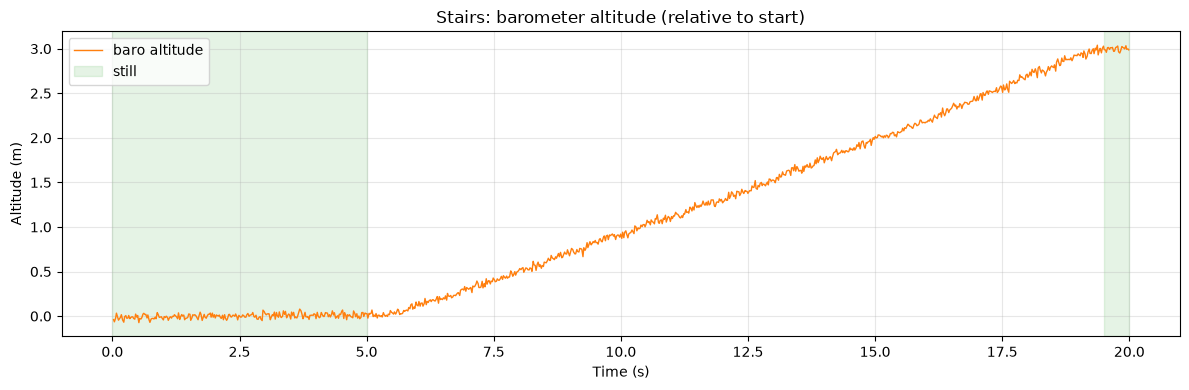

In [25]:
# Plot raw data with the still windows shaded
utils.plot_traces(
    [(t_acc_s, az_s, "az", {"color": "tab:blue"})],
    "Acceleration (m/s²)",
    title="Stairs: raw z-axis acceleration",
    windows=windows,
)
utils.plot_traces(
    [(t_baro_s, alt_s_rel, "baro altitude", {"color": "tab:orange"})],
    "Altitude (m)",
    title="Stairs: barometer altitude (relative to start)",
    windows=windows,
)

### Measured Height Change

Averaging the barometer over each still window removes most of its noise. The difference between the first and last windows gives a measured height change, which we can check against the step count.

In [26]:
# Average barometer altitude in each still window
for i, w in enumerate(windows):
    print(f"Window {i}: mean altitude = {utils.window_mean(t_baro_s, alt_s_rel, w):+.3f} m")

# Height change: measured (barometer) vs. expected (steps x riser height)
dh_baro = (utils.window_mean(t_baro_s, alt_s_rel, windows[-1])
           - utils.window_mean(t_baro_s, alt_s_rel, windows[0]))
dh_true = NUM_STEPS * RISER_M
print()
print(f"Height change from steps:     {dh_true:.3f} m")
print(f"Height change from barometer: {dh_baro:.3f} m")

Window 0: mean altitude = +0.000 m
Window 1: mean altitude = +2.998 m

Height change from steps:     3.088 m
Height change from barometer: 2.998 m


## Stairs Recording: Accelerometer Only

Same approach as the static recording: remove gravity using the first still window, then double-integrate.

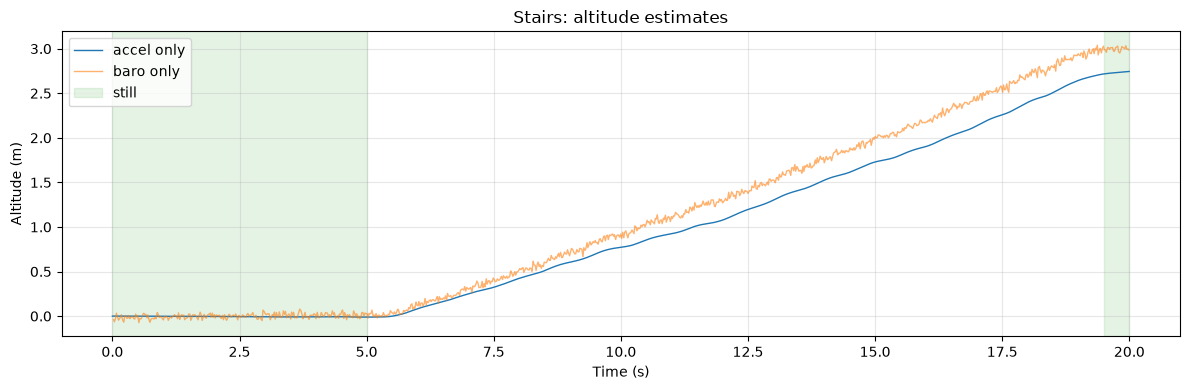

In [28]:
# Remove gravity and bias, then double-integrate
a_s, g_est_s = accel_to_vertical(t_acc_s, az_s, windows[0])
v_acc_s, h_acc_s = integrate_accel(t_acc_s, a_s)

# Plot altitude: accelerometer vs. barometer
utils.plot_traces(
    [
        (t_acc_s, h_acc_s, "accel only", {"color": "tab:blue"}),
        (t_baro_s, alt_s_rel, "baro only", {"color": "tab:orange", "alpha": 0.6}),
    ],
    "Altitude (m)",
    title="Stairs: altitude estimates",
    windows=windows,
)

## Stairs Recording: Barometer Velocity

The barometer measures altitude directly, so the obvious way to get velocity is to differentiate it: subtract consecutive readings and divide by the time between them. Dividing small, noisy differences by a short time step amplifies the noise enormously.

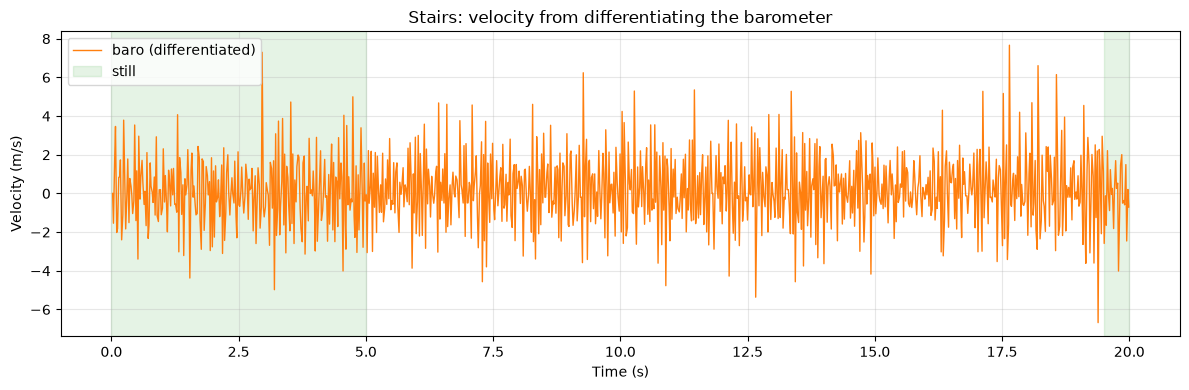

Predicted velocity noise: sqrt(2) * sigma_b / dt = 2.33 m/s
Measured (still windows): 1.79 m/s


In [29]:
# Differentiate barometer altitude
v_baro = velocity_from_baro(t_baro_s, alt_s_rel)

# Plot raw barometer velocity
utils.plot_traces(
    [(t_baro_s, v_baro, "baro (differentiated)", {"color": "tab:orange"})],
    "Velocity (m/s)",
    title="Stairs: velocity from differentiating the barometer",
    windows=windows,
)

# Noise check: differencing scales the noise by sqrt(2) / dt
dt_baro = np.median(np.diff(t_baro_s))
print(f"Predicted velocity noise: sqrt(2) * sigma_b / dt = "
      f"{np.sqrt(2) * sigma_b / dt_baro:.2f} m/s")
print(f"Measured (still windows): "
      f"{utils.rms_in_windows(t_baro_s, v_baro, windows):.2f} m/s")

We can smooth the barometer velocity with a moving average, but a real-time average only uses past data, so it lags behind the true motion. The more we smooth, the more it lags.

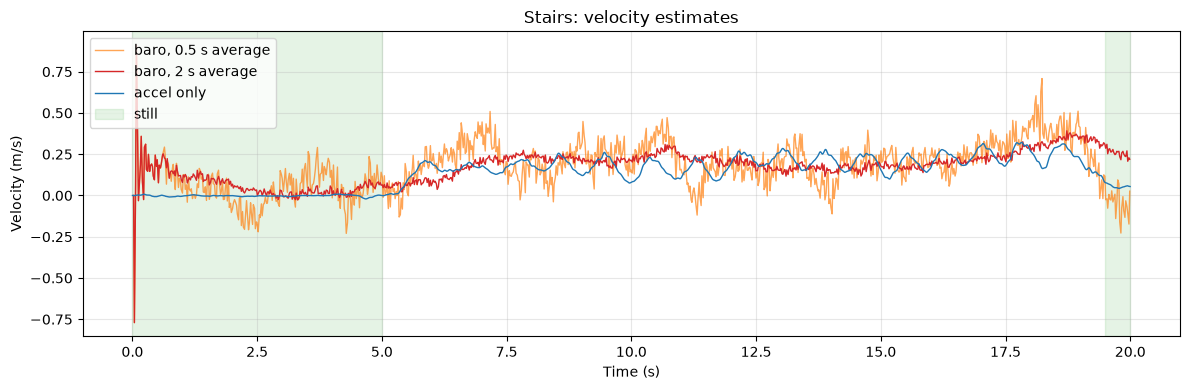

In [30]:
# Smooth the barometer velocity over 0.5 s and 2 s
baro_rate_s = 1 / dt_baro
v_baro_05 = moving_average(v_baro, int(0.5 * baro_rate_s))
v_baro_2 = moving_average(v_baro, int(2.0 * baro_rate_s))

# Compare with the accelerometer velocity
utils.plot_traces(
    [
        (t_baro_s, v_baro_05, "baro, 0.5 s average", {"color": "tab:orange", "alpha": 0.7}),
        (t_baro_s, v_baro_2, "baro, 2 s average", {"color": "tab:red"}),
        (t_acc_s, v_acc_s, "accel only", {"color": "tab:blue"}),
    ],
    "Velocity (m/s)",
    title="Stairs: velocity estimates",
    windows=windows,
)

## Stairs Recording: Scorecard

We don't have a reference sensor for velocity, but we know the true velocity is zero during the still windows, and we know the true height change from the step count.

In [31]:
# Velocity error during still windows (true velocity = 0)
print("Velocity RMS during still windows (should be 0):")
print(f"  accel only:          {utils.rms_in_windows(t_acc_s, v_acc_s, windows):.3f} m/s")
print(f"  baro (raw):          {utils.rms_in_windows(t_baro_s, v_baro, windows):.3f} m/s")
print(f"  baro (0.5 s avg):    {utils.rms_in_windows(t_baro_s, v_baro_05, windows):.3f} m/s")
print(f"  baro (2 s avg):      {utils.rms_in_windows(t_baro_s, v_baro_2, windows):.3f} m/s")

# Height change error (last still window minus first)
dh_acc = (utils.window_mean(t_acc_s, h_acc_s, windows[-1])
          - utils.window_mean(t_acc_s, h_acc_s, windows[0]))
print()
print(f"Height change (true = {dh_true:.3f} m):")
print(f"  accel only:          {dh_acc:.3f} m  (error {dh_acc - dh_true:+.3f} m)")
print(f"  baro only:           {dh_baro:.3f} m  (error {dh_baro - dh_true:+.3f} m)")

Velocity RMS during still windows (should be 0):
  accel only:          0.018 m/s
  baro (raw):          1.793 m/s
  baro (0.5 s avg):    0.141 m/s
  baro (2 s avg):      0.139 m/s

Height change (true = 3.088 m):
  accel only:          2.737 m  (error -0.351 m)
  baro only:           2.998 m  (error -0.090 m)


## Takeaways

| | Accelerometer | Barometer |
|---|---|---|
| Short term | Smooth and responsive | Noisy |
| Long term | Drifts (½·b·t² for altitude) | Wanders, but stays bounded |
| Altitude | Only for a few seconds | Good, once averaged |
| Velocity | Good for a few seconds, then drifts | Very noisy, or laggy if smoothed |

Each sensor is strong exactly where the other is weak. In the next notebook, we combine them with a Kalman filter: the accelerometer *predicts* how h and v change between samples, and the barometer *corrects* the altitude, which also pulls the velocity back on track.